# 🗄️ Mineração de Dados
## Módulo 1: Introdução à Mineração de Dados e Descoberta de Conhecimento (KDD)

---

## 🎯 Objetivos deste Notebook

Ao concluir este notebook, você será capaz de:

1. ✅ Carregar e explorar datasets reais com Pandas e Scikit-learn
2. ✅ Realizar Análise Exploratória de Dados (EDA) completa
3. ✅ Implementar o pipeline CRISP-DM na prática


---

## 📋 Sumário

1. [Setup e Importações](#setup)
2. [Explorando Dados Reais — Dataset Wine](#wine)
3. [Análise Exploratória de Dados (EDA)](#eda)
4. [Pipeline CRISP-DM na Prática](#crispdm)


In [ ]:
# Instalação das dependências necessárias
# Execute esta célula apenas uma vez (especialmente no Google Colab)
!pip install -q scikit-learn pandas numpy matplotlib seaborn scipy plotly kaleido
print('Instalação concluída!')

## 📦 1. Setup e Importações <a id='setup'></a>

Importamos todas as bibliotecas necessárias e configuramos o ambiente para reprodutibilidade.


In [1]:
# ============================================================
# IMPORTAÇÕES PRINCIPAIS
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import scipy
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
import time

# Algoritmos de Machine Learning
from sklearn.datasets import load_wine, make_classification
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Configurações globais
warnings.filterwarnings('ignore')          # Suprimir avisos para clareza
np.random.seed(42)                          # Semente para reprodutibilidade

# Estilo dos gráficos Matplotlib
plt.style.use('seaborn-v0_8-whitegrid')
matplotlib.rcParams['figure.figsize'] = (12, 6)
matplotlib.rcParams['font.size'] = 11
matplotlib.rcParams['axes.titlesize'] = 13
matplotlib.rcParams['axes.labelsize'] = 11
sns.set_palette('husl')                     # Paleta de cores harmoniosa

# Imprimir versões das bibliotecas para documentação
print('=' * 55)
print('VERSÕES DAS BIBLIOTECAS CARREGADAS')
print('=' * 55)
import sklearn
print(f'NumPy:        {np.__version__}')
print(f'Pandas:       {pd.__version__}')
print(f'Matplotlib:   {matplotlib.__version__}')
print(f'Seaborn:      {sns.__version__}')
print(f'Scikit-learn: {sklearn.__version__}')
print(f'SciPy:        {scipy.__version__}')
print('=' * 55)
print('Ambiente configurado com sucesso!')

VERSÕES DAS BIBLIOTECAS CARREGADAS
NumPy:        1.26.4
Pandas:       2.3.3
Matplotlib:   3.10.0
Seaborn:      0.13.2
Scikit-learn: 1.9.0
SciPy:        1.16.3
Ambiente configurado com sucesso!


## 🗄️ 2. Explorando Dados Reais — Dataset Wine <a id='wine'></a>

O **Dataset Wine** contém 178 amostras de vinhos italianos de 3 cultivares diferentes,
descritos por 13 atributos físico-químicos. É um clássico para estudar classificação
e análise exploratória de dados.

**Referência:** Forina et al. (1986) — UCI Machine Learning Repository


In [2]:
# ============================================================
# CARREGANDO E ESTRUTURANDO O DATASET WINE
# ============================================================

# Carregar o dataset do scikit-learn
wine_data = load_wine()

# Converter para DataFrame do Pandas para facilitar a análise
df = pd.DataFrame(
    data=wine_data.data,
    columns=wine_data.feature_names   # Usar os nomes originais das features
)
df['target'] = wine_data.target        # Adicionar coluna alvo (0, 1, 2)
df['cultivar'] = df['target'].map({   # Mapear para nomes descritivos
    0: 'Cultivar_A',
    1: 'Cultivar_B',
    2: 'Cultivar_C'
})

# Informações básicas do dataset
print('=' * 55)
print('INFORMAÇÕES GERAIS DO DATASET WINE')
print('=' * 55)
print(f'Dimensões: {df.shape[0]} linhas x {df.shape[1]} colunas')
print(f'Features:  {len(wine_data.feature_names)}')
print(f'Classes:   {list(wine_data.target_names)}')
print()

# Primeiras linhas
print('Primeiras 5 linhas do dataset:')
display(df.head())

# Tipos de dados
print('\nTipos de dados por coluna:')
print(df.dtypes)

INFORMAÇÕES GERAIS DO DATASET WINE
Dimensões: 178 linhas x 15 colunas
Features:  13
Classes:   ['class_0', 'class_1', 'class_2']

Primeiras 5 linhas do dataset:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,Cultivar_A
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,Cultivar_A
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,Cultivar_A
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,Cultivar_A
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,Cultivar_A



Tipos de dados por coluna:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
cultivar                         object
dtype: object


In [3]:
# ============================================================
# DIAGNÓSTICO DETALHADO DOS DADOS
# ============================================================

print('VALORES AUSENTES POR COLUNA')
print('-' * 40)
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else 'Nenhum valor ausente encontrado!')

print('\nDISTRIBUIÇÃO DAS CLASSES (Target)')
print('-' * 40)
class_dist = df['cultivar'].value_counts()
for cls, count in class_dist.items():
    pct = count / len(df) * 100
    print(f'  {cls}: {count} amostras ({pct:.1f}%)')

print('\nESTATÍSTICAS DESCRITIVAS GERAIS')
print('-' * 40)
display(df.describe().round(2))

print('\nESTATÍSTICAS POR CULTIVAR (média de cada feature)')
print('-' * 40)
# Agrupar por cultivar e calcular médias
display(df.groupby('cultivar')[wine_data.feature_names].mean().round(2))

VALORES AUSENTES POR COLUNA
----------------------------------------
Nenhum valor ausente encontrado!

DISTRIBUIÇÃO DAS CLASSES (Target)
----------------------------------------
  Cultivar_B: 71 amostras (39.9%)
  Cultivar_A: 59 amostras (33.1%)
  Cultivar_C: 48 amostras (27.0%)

ESTATÍSTICAS DESCRITIVAS GERAIS
----------------------------------------


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89,0.94
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91,0.78
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00,0.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50,0.00
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50,1.00
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00,2.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00,2.00



ESTATÍSTICAS POR CULTIVAR (média de cada feature)
----------------------------------------


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
cultivar,,,,,,,,,,,,,
Cultivar_A,13.74,2.01,2.46,17.04,106.34,2.84,2.98,0.29,1.90,5.53,1.06,3.16,1115.71
Cultivar_B,12.28,1.93,2.24,20.24,94.55,2.26,2.08,0.36,1.63,3.09,1.06,2.79,519.51
Cultivar_C,13.15,3.33,2.44,21.42,99.31,1.68,0.78,0.45,1.15,7.40,0.68,1.68,629.90


## 📊 3. Análise Exploratória de Dados (EDA) <a id='eda'></a>

A EDA é fundamental para entender a estrutura dos dados antes de aplicar qualquer algoritmo.
Visualizamos distribuições, correlações e separabilidade das classes.


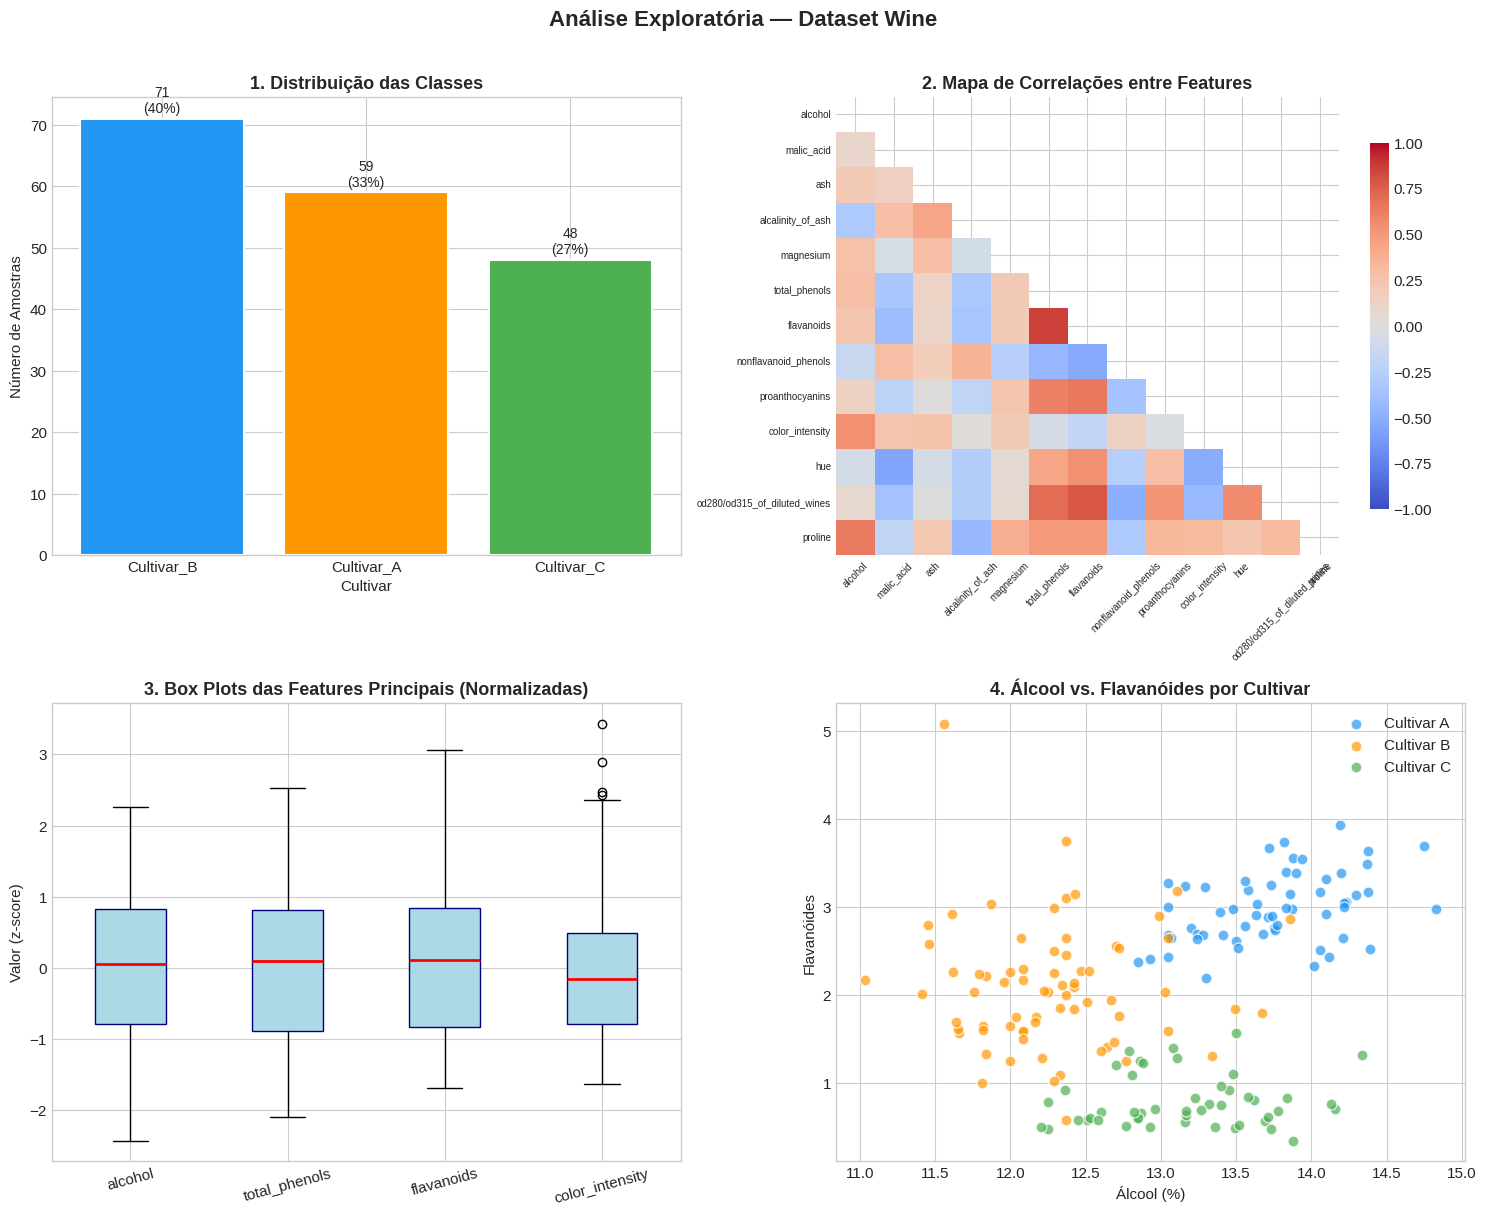

Painel EDA gerado com sucesso!


In [4]:
# ============================================================
# VISUALIZAÇÕES EDA — PAINEL PRINCIPAL (2x2)
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Análise Exploratória — Dataset Wine', fontsize=16, fontweight='bold', y=1.01)

# --- Gráfico 1: Distribuição das classes (barras) ---
ax1 = axes[0, 0]
colors_bar = ['#2196F3', '#FF9800', '#4CAF50']
class_counts = df['cultivar'].value_counts()
bars = ax1.bar(class_counts.index, class_counts.values, color=colors_bar, edgecolor='white', linewidth=1.5)
# Adicionar rótulos nas barras
for bar, count in zip(bars, class_counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5,
             f'{count}\n({count/len(df)*100:.0f}%)', ha='center', va='bottom', fontsize=10)
ax1.set_title('1. Distribuição das Classes', fontweight='bold')
ax1.set_xlabel('Cultivar')
ax1.set_ylabel('Número de Amostras')

# --- Gráfico 2: Mapa de calor de correlações ---
ax2 = axes[0, 1]
# Selecionar apenas colunas numéricas
corr_matrix = df[wine_data.feature_names].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # Ocultar triângulo superior
sns.heatmap(corr_matrix, mask=mask, annot=False, cmap='coolwarm',
            center=0, vmin=-1, vmax=1, ax=ax2, cbar_kws={'shrink': 0.8})
ax2.set_title('2. Mapa de Correlações entre Features', fontweight='bold')
ax2.tick_params(axis='x', rotation=45, labelsize=7)
ax2.tick_params(axis='y', labelsize=7)

# --- Gráfico 3: Box plots das 4 features mais importantes ---
ax3 = axes[1, 0]
top_features = ['alcohol', 'total_phenols', 'flavanoids', 'color_intensity']
# Normalizar para comparação visual (z-score)
df_norm = df[top_features].copy()
for col in top_features:
    df_norm[col] = (df_norm[col] - df_norm[col].mean()) / df_norm[col].std()
ax3.boxplot([df_norm[f] for f in top_features], labels=top_features, patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='navy'),
            medianprops=dict(color='red', linewidth=2))
ax3.set_title('3. Box Plots das Features Principais (Normalizadas)', fontweight='bold')
ax3.set_ylabel('Valor (z-score)')
ax3.tick_params(axis='x', rotation=15)

# --- Gráfico 4: Scatter plot das 2 primeiras features colorido por classe ---
ax4 = axes[1, 1]
colors_scatter = {0: '#2196F3', 1: '#FF9800', 2: '#4CAF50'}
for cultivar_id, color in colors_scatter.items():
    mask_cls = df['target'] == cultivar_id
    ax4.scatter(df[mask_cls]['alcohol'], df[mask_cls]['flavanoids'],
                c=color, label=f'Cultivar {["A","B","C"][cultivar_id]}',
                alpha=0.7, edgecolors='white', s=60)
ax4.set_title('4. Álcool vs. Flavanóides por Cultivar', fontweight='bold')
ax4.set_xlabel('Álcool (%)')
ax4.set_ylabel('Flavanóides')
ax4.legend(loc='best')

plt.tight_layout()
plt.show()
print('Painel EDA gerado com sucesso!')

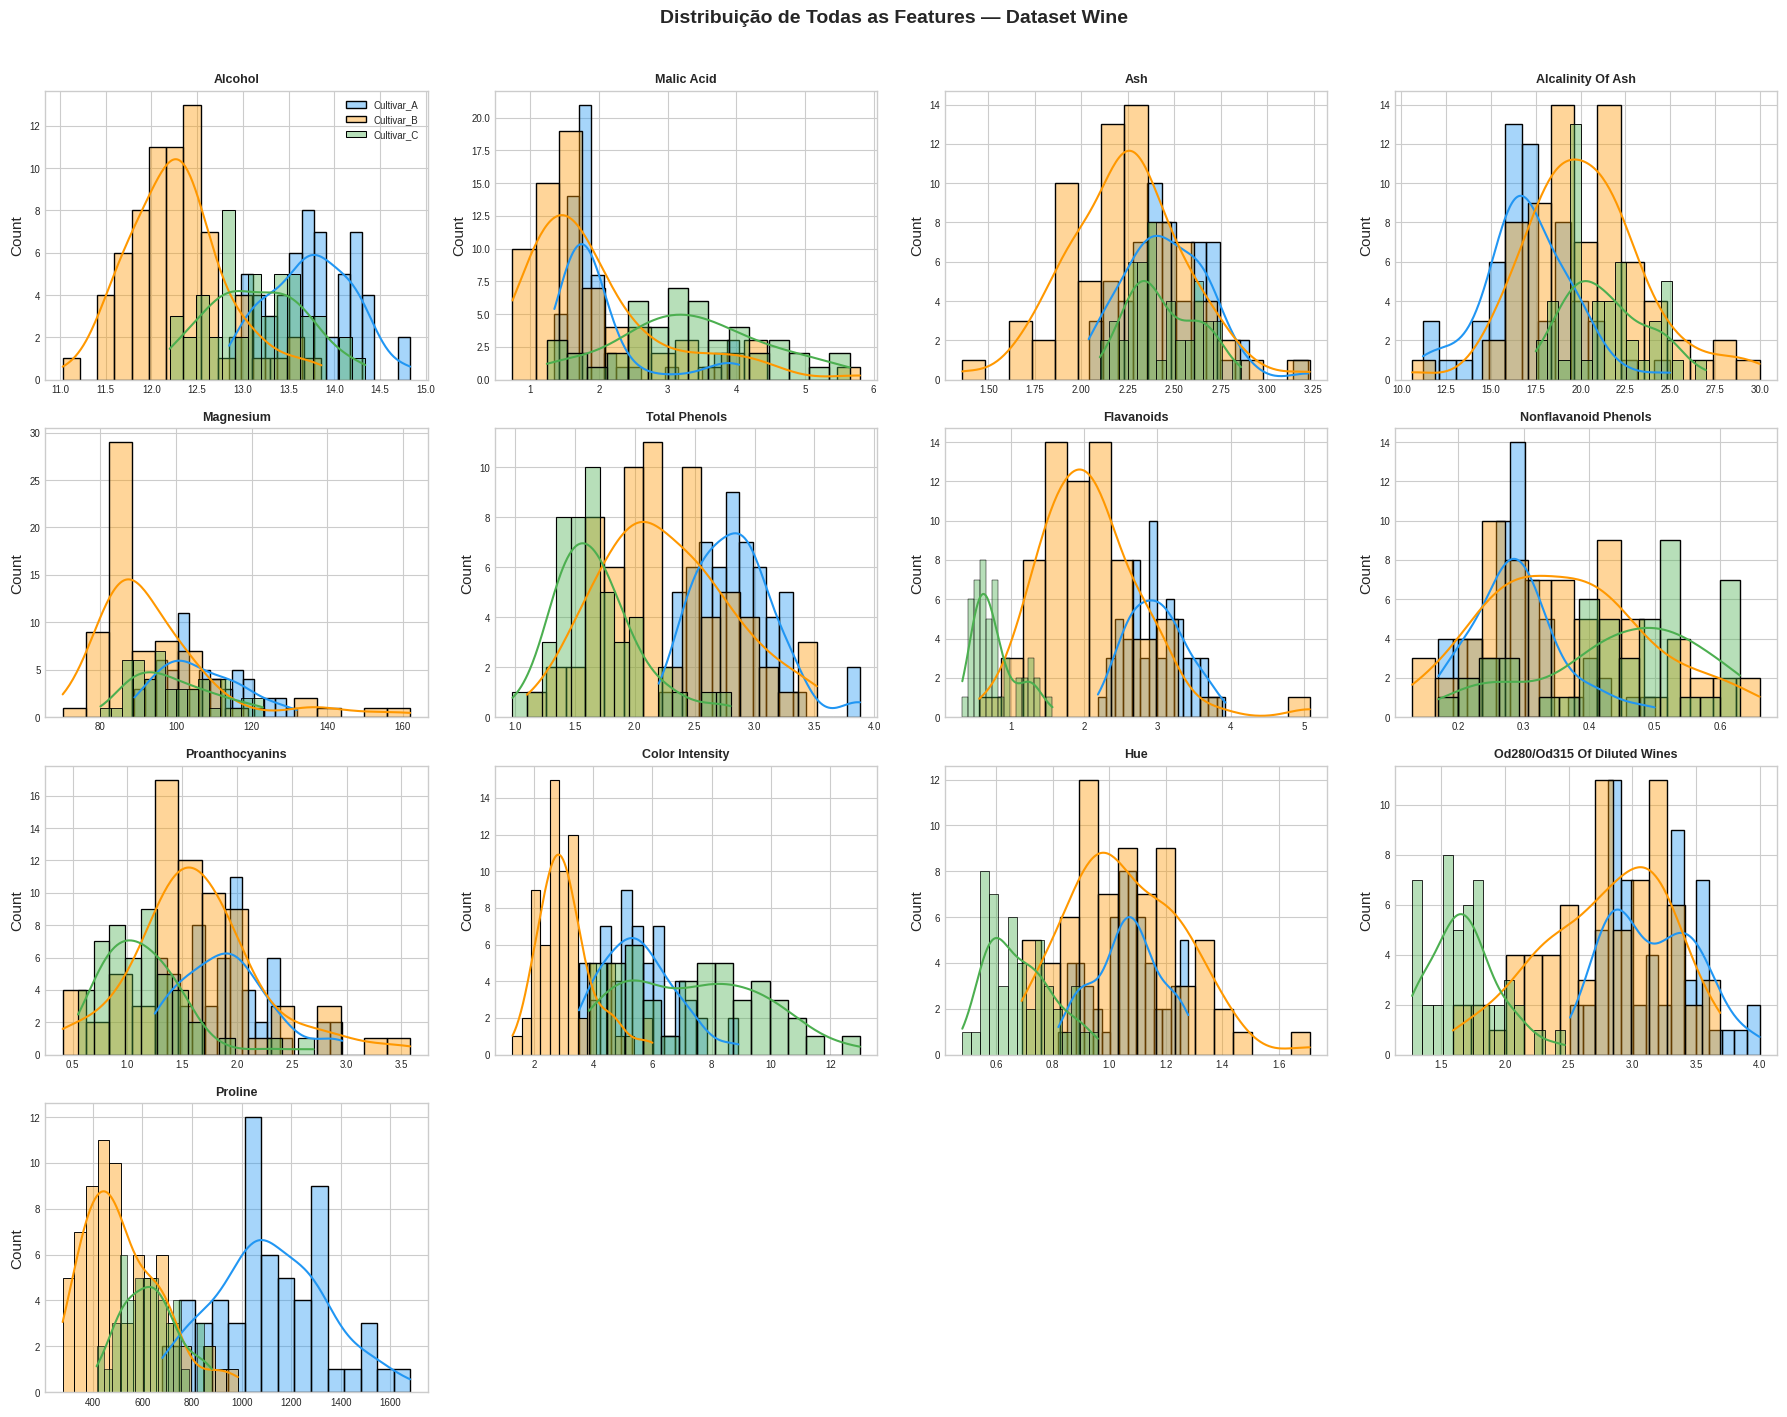

Distribuições de 13 features plotadas!
Figura salva como wine_distributions.png


In [5]:
# ============================================================
# DISTRIBUIÇÃO DE TODAS AS 13 FEATURES
# ============================================================

features = wine_data.feature_names
n_features = len(features)      # 13 features
n_cols = 4
n_rows = (n_features + n_cols - 1) // n_cols  # Calcular linhas necessárias

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 14))
fig.suptitle('Distribuição de Todas as Features — Dataset Wine',
             fontsize=14, fontweight='bold', y=1.01)

# Paleta de cores para as 3 classes
palette = {'Cultivar_A': '#2196F3', 'Cultivar_B': '#FF9800', 'Cultivar_C': '#4CAF50'}

for idx, feature in enumerate(features):
    row, col = divmod(idx, n_cols)
    ax = axes[row, col]
    # Histograma com KDE para cada cultivar
    for cultivar, color in palette.items():
        data_subset = df[df['cultivar'] == cultivar][feature]
        sns.histplot(data_subset, kde=True, ax=ax, color=color,
                     alpha=0.4, label=cultivar, bins=15)
    ax.set_title(feature.replace('_', ' ').title(), fontsize=9, fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(labelsize=7)
    if idx == 0:  # Legenda apenas no primeiro gráfico
        ax.legend(fontsize=7)

# Ocultar eixos extras (caso n_features não preencha a grade)
for idx in range(n_features, n_rows * n_cols):
    row, col = divmod(idx, n_cols)
    axes[row, col].set_visible(False)

plt.tight_layout()
plt.savefig('wine_distributions.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'Distribuições de {n_features} features plotadas!')
print('Figura salva como wine_distributions.png')

## ⚙️ 4. Pipeline CRISP-DM na Prática <a id='crispdm'></a>

Implementamos as fases do CRISP-DM de forma estruturada para o dataset Wine.
Cada fase é documentada e os resultados são apresentados de forma clara.


In [6]:
# ============================================================
# IMPLEMENTAÇÃO DO PIPELINE CRISP-DM
# ============================================================

print('=' * 60)
print('PIPELINE CRISP-DM: CLASSIFICAÇÃO DE VINHOS')
print('=' * 60)

# --- FASE 1: Entendimento do Negócio ---
business_understanding = {
    'problema': 'Classificar automaticamente vinhos por cultivar',
    'objetivo_negocio': 'Automatizar controle de qualidade na produção',
    'metrica_sucesso': 'Acurácia >= 95% em dados de teste',
    'restricoes': 'Modelo deve ser interpretável pelo enólogo'
}
print('\n[FASE 1] Entendimento do Negócio')
for k, v in business_understanding.items():
    print(f'  {k.replace("_", " ").title()}: {v}')

# --- FASE 2: Entendimento dos Dados ---
print('\n[FASE 2] Entendimento dos Dados')
X = df[wine_data.feature_names].values   # Matriz de features
y = df['target'].values                   # Vetor alvo
print(f'  Amostras: {X.shape[0]}, Features: {X.shape[1]}, Classes: {len(np.unique(y))}')
print(f'  Valores ausentes: {np.isnan(X).sum()}')
print(f'  Range de valores: [{X.min():.2f}, {X.max():.2f}]')

# --- FASE 3: Preparação dos Dados ---
print('\n[FASE 3] Preparação dos Dados')
# Dividir em treino (80%) e teste (20%), estratificando por classe
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'  Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras')

# --- FASE 4: Modelagem com sklearn Pipeline ---
print('\n[FASE 4] Modelagem (Pipeline: Scaler + RandomForest)')
# Pipeline que garante que o scaler seja ajustado apenas nos dados de treino
pipeline = Pipeline([
    ('scaler', StandardScaler()),              # Passo 1: normalização
    ('clf', RandomForestClassifier(
        n_estimators=100,                      # 100 árvores no ensemble
        max_depth=5,                           # Profundidade máxima
        random_state=42
    ))
])
pipeline.fit(X_train, y_train)               # Treinar no conjunto de treino
y_pred = pipeline.predict(X_test)            # Predizer no conjunto de teste

# --- FASE 5: Avaliação ---
print('\n[FASE 5] Avaliação')
acc = accuracy_score(y_test, y_pred)
print(f'  Acurácia no Teste: {acc:.4f} ({acc*100:.2f}%)')
print()
print('  Relatório de Classificação:')
target_names = [f'Cultivar_{c}' for c in ['A', 'B', 'C']]
print(classification_report(y_test, y_pred, target_names=target_names, digits=4))

# --- FASE 6: Implantação (simulada) ---
print('[FASE 6] Implantação')
print('  Modelo treinado e pronto para deploy!')
print('  Próximo passo: serializar com joblib.dump() e servir via API REST.')

PIPELINE CRISP-DM: CLASSIFICAÇÃO DE VINHOS

[FASE 1] Entendimento do Negócio
  Problema: Classificar automaticamente vinhos por cultivar
  Objetivo Negocio: Automatizar controle de qualidade na produção
  Metrica Sucesso: Acurácia >= 95% em dados de teste
  Restricoes: Modelo deve ser interpretável pelo enólogo

[FASE 2] Entendimento dos Dados
  Amostras: 178, Features: 13, Classes: 3
  Valores ausentes: 0
  Range de valores: [0.13, 1680.00]

[FASE 3] Preparação dos Dados
  Treino: 142 amostras | Teste: 36 amostras

[FASE 4] Modelagem (Pipeline: Scaler + RandomForest)

[FASE 5] Avaliação
  Acurácia no Teste: 1.0000 (100.00%)

  Relatório de Classificação:
              precision    recall  f1-score   support

  Cultivar_A     1.0000    1.0000    1.0000        12
  Cultivar_B     1.0000    1.0000    1.0000        14
  Cultivar_C     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted a

In [ ]:
# ============================================================
# VALIDAÇÃO CRUZADA (5-FOLD STRATIFIED CV)
# ============================================================

print('VALIDAÇÃO CRUZADA — 5-Fold Estratificado')
print('=' * 55)

# Configurar validação cruzada estratificada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Executar CV e coletar scores por fold
scores = cross_val_score(
    pipeline, X, y,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1          # Usar todos os núcleos disponíveis
)

# Exibir resultados em tabela formatada
print(f"{'Fold':>6} | {'Acurácia':>10} | {'Desvio da Média':>15}")
print('-' * 38)
for i, score in enumerate(scores, 1):
    desvio = score - scores.mean()
    sinal = '+' if desvio >= 0 else ''
    print(f"{'Fold ' + str(i):>6} | {score:.4f}     | {sinal}{desvio:.4f}")
print('-' * 38)
print(f"{'Média':>6} | {scores.mean():.4f}     | ± {scores.std():.4f}")
print()
print(f'Acurácia média: {scores.mean()*100:.2f}% (±{scores.std()*100:.2f}%)')
print(f'Intervalo de confiança (95%): [{(scores.mean()-2*scores.std())*100:.2f}%, {(scores.mean()+2*scores.std())*100:.2f}%]')